# Predicting CO₂ uptake: what does the test score estimate?

Adapted from Kevin Jablonka's [MolSim 2024 practical](https://github.com/kjappelbaum/ml_molsim/tree/0ebed176b972c9ba9ddf7b6e3a4d04eaf3f32409).
We retain its MOF question, descriptors, baselines, kernel ridge regression,
and model-inspection idea. This smaller version runs from beginning to end.
Change one choice, predict its effect, and explain the result.

The distributed notebook includes saved test results. The supplied run
chose its model using validation data. Once you have inspected its test
results, changes to your model are exploratory; the same test rows cannot
provide a fresh, untouched assessment of the revised procedure.

The targets are **computed** pure CO₂ uptakes at 298 K and 1.6 MPa (16 bar),
in mmol/g. We are approximating simulation results. The 1,500-row subset
and source-row identifiers are supplied locally; no account or live data
download is needed while running this notebook.

From the project folder, use `uv sync --locked --group mof`, then
`uv run --locked --group mof jupyter lab --no-browser`.
Windows users run those commands in Ubuntu on WSL.

## 1. Find the data and define the question

A metal–organic framework (MOF) connects metal-containing nodes with organic
linkers. Pores provide space for gas molecules. Here, pore diameters,
surface areas, pore volumes, and density are **descriptors**: numerical
descriptions that we choose to supply to the model.

These eight geometric quantities omit much of the chemistry. Keep that
omission in mind when asking what a useful prediction would establish.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

# Works when Jupyter starts in the project or its notebooks/ directory.
root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'data/mof-uptake/provenance.json').exists()), None)
if root is None:
    raise FileNotFoundError('Extract the complete MOF practical folder, including data/.')
data_dir = root / 'data/mof-uptake'
provenance = json.loads((data_dir / 'provenance.json').read_text())
data_file = data_dir / 'mof-uptake.csv'
assert hashlib.sha256(data_file.read_bytes()).hexdigest() == provenance['subset_sha256']
data = pd.read_csv(data_file)
FEATURES = provenance['features']
TARGET = provenance['target']
assert len(data) == provenance['subset_rows'] == 1500
assert data['MOFname'].is_unique and data['source_row'].is_unique
assert np.isfinite(data[FEATURES + [TARGET]].to_numpy()).all()
assert TARGET not in FEATURES
print(f'{len(data)} rows; {len(FEATURES)} input features; target units: mmol/g')
print('Source revision:', provenance['commit'])

1500 rows; 8 input features; target units: mmol/g
Source revision: 0ebed176b972c9ba9ddf7b6e3a4d04eaf3f32409


## 2. Give each set of observations a job

We use a fixed random split: 900 training, 300 validation, and 300 test rows.
Inspect and compare models with training and validation data. Leave the
final test evaluation until the procedure is chosen.

This is an exercise in predicting other rows from this collection. Different
MOF names can share building blocks. A random row split does not establish
performance on a new framework family, a different simulation protocol,
or experimentally measured uptake.

In [2]:
development, test = train_test_split(data, test_size=0.20, random_state=24)
train, validation = train_test_split(development, test_size=0.25, random_state=25)
parts = [set(frame['source_row']) for frame in (train, validation, test)]
assert all(parts[i].isdisjoint(parts[j]) for i in range(3) for j in range(i+1, 3))
print('Training / validation / test:', len(train), len(validation), len(test))
display(train[['MOFname'] + FEATURES + [TARGET]].head(5))

Training / validation / test: 900 300 300


,MOFname,Di,Df,Dif,density [g/cm^3],total_SA_volumetric,total_SA_gravimetric,total_POV_volumetric,total_POV_gravimetric,pure_uptake_CO2_298.00_1600000
823,str_m4_o4_o5_acs_sym.55,4.29622,2.90888,4.01241,1.36004,58.66690,43.136158,0.07078,0.052042,4.251235
810,str_m4_o4_o24_acs_sym.159,5.08892,3.56071,5.08541,1.33094,470.90100,353.810840,0.23564,0.177047,5.444129
1018,str_m5_o2_o22_sra_sym.33,3.79084,1.92873,3.76567,1.34510,3.70703,2.755951,0.00000,0.000000,2.882556
1045,str_m5_o4_o16_sra_sym.12,4.39216,3.45293,4.39216,1.15471,207.31500,179.538585,0.20732,0.179543,7.191544
735,str_m4_o1_o14_acs_sym.86,4.09882,2.13361,4.08647,1.54217,30.75390,19.941965,0.01956,0.012683,2.809840


**Before running the plot:** do you expect increasing pore volume to
coincide with increasing uptake? What chemical information is missing
from this comparison? A pandas `DataFrame` is a table; `train[column]`
selects one column from it.

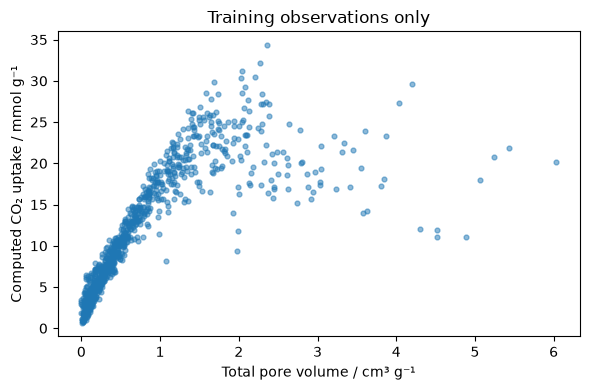

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(train['total_POV_gravimetric'], train[TARGET], s=12, alpha=0.5)
ax.set(xlabel='Total pore volume / cm³ g⁻¹', ylabel='Computed CO₂ uptake / mmol g⁻¹',
       title='Training observations only')
plt.tight_layout()
plt.show()

## 3. Compare a baseline and three models

The baseline predicts the median training uptake for every MOF. Why is the
median a sensible constant when we compare mean absolute errors (MAE)?

Ridge regression fits a linear relationship with a penalty on coefficients.
Kernel ridge regression (KRR) can describe a nonlinear relationship using
similarities between feature vectors. Here the Gaussian kernel uses
distances; changing the feature scales changes those distances.

A **pipeline** keeps scaling and fitting together. Its scaler learns only
from the training rows. The two KRR candidates use the same settings,
`alpha=1` and `gamma=0.1`; one also scales the features. These settings are
choices, not claims of optimality. Predict which comparison will be most
informative before executing.

In [4]:
candidates = {
    'Training median': DummyRegressor(strategy='median'),
    'Scaled ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Unscaled KRR': KernelRidge(alpha=1.0, gamma=0.1, kernel='rbf'),
    'Scaled KRR': make_pipeline(StandardScaler(),
                               KernelRidge(alpha=1.0, gamma=0.1, kernel='rbf')),
}
X_train, y_train = train[FEATURES], train[TARGET]
X_validation, y_validation = validation[FEATURES], validation[TARGET]
scores = []
for name, model in candidates.items():
    model.fit(X_train, y_train)
    scores.append({'model': name,
                   'training_MAE': mean_absolute_error(y_train, model.predict(X_train)),
                   'validation_MAE': mean_absolute_error(y_validation, model.predict(X_validation))})
comparison = pd.DataFrame(scores).set_index('model')
display(comparison.round(3))
selected_name = comparison['validation_MAE'].idxmin()
selected_model = candidates[selected_name]
print('Chosen by validation MAE:', selected_name)
# Check that the fitted scaler contains only training-set statistics.
np.testing.assert_allclose(candidates['Scaled KRR'][0].mean_, X_train.mean().to_numpy())

,training_MAE,validation_MAE
model,,
Training median,6.197,6.368
Scaled ridge,1.523,1.297
Unscaled KRR,5.820,11.077
Scaled KRR,1.284,1.149


Chosen by validation MAE: Scaled KRR


**Try before final evaluation:** change one KRR setting or remove one
feature, rerun from the start, and compare validation results. Record the
choice you will keep before proceeding to section 5. Once you have inspected
the test result, further changes make this an exploratory exercise and
need fresh data for a new final assessment.

The diagonal in a **parity plot** marks exact agreement with the simulation
labels. Both axes concern computed quantities; “reference” does not mean
that the simulation is free of physical or numerical approximations.

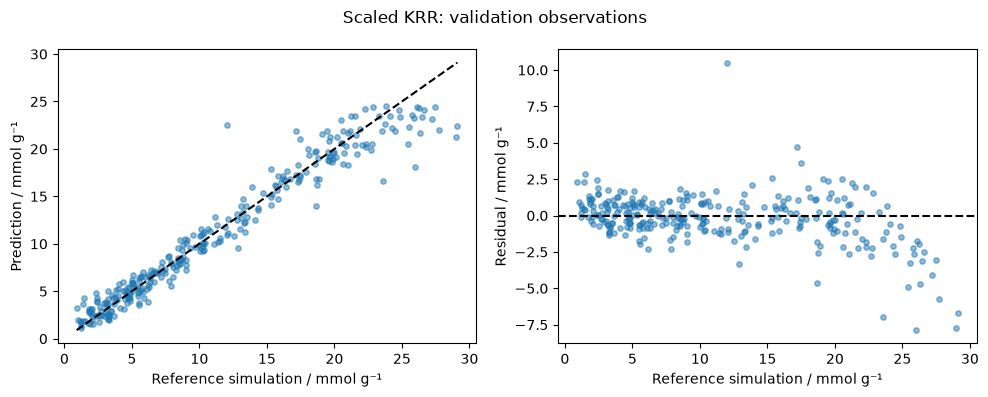

In [5]:
validation_predictions = selected_model.predict(X_validation)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(y_validation, validation_predictions, s=15, alpha=0.5)
limits = [min(y_validation.min(), validation_predictions.min()),
          max(y_validation.max(), validation_predictions.max())]
axes[0].plot(limits, limits, color='black', linestyle='--')
axes[0].set(xlabel='Reference simulation / mmol g⁻¹', ylabel='Prediction / mmol g⁻¹')
axes[1].scatter(y_validation, validation_predictions-y_validation, s=15, alpha=0.5)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Reference simulation / mmol g⁻¹', ylabel='Residual / mmol g⁻¹')
fig.suptitle(f'{selected_name}: validation observations')
plt.tight_layout()
plt.show()

## 4. Optional: inspect dependence on a feature

Shuffle one validation column while keeping the fitted model fixed. If
MAE increases, the model used information disrupted by that shuffle.
The library repeats the shuffle so we can see how the result varies.

Does shuffling pore volume independently of density create plausible
materials? Correlated descriptors complicate this interpretation. This
operation concerns the model and the chosen data; it is not an experiment
that changes pore volume in a synthesised MOF.

In [6]:
importance = permutation_importance(
    selected_model, X_validation, y_validation,
    scoring='neg_mean_absolute_error', n_repeats=5, random_state=26, n_jobs=1)
inspection = pd.DataFrame({'feature': FEATURES,
                           'MAE_increase': importance.importances_mean,
                           'shuffle_SD': importance.importances_std})
display(inspection.sort_values('MAE_increase', ascending=False).round(3))

,feature,MAE_increase,shuffle_SD
6,total_POV_volumetric,1.830,0.110
3,density [g/cm^3],1.811,0.082
5,total_SA_gravimetric,1.766,0.127
4,total_SA_volumetric,1.088,0.120
7,total_POV_gravimetric,1.042,0.080
1,Df,0.776,0.075
0,Di,0.717,0.074
2,Dif,0.656,0.073


## 5. Freeze the choice, then estimate test error

We retain the model fitted on the training data, with no refit or tuning on
test observations. Compare it with the predeclared median baseline. Which
population can these test rows represent? What would be different if we
wanted to predict uptake in an experimental sample?

In [7]:
test_predictions = selected_model.predict(test[FEATURES])
test_baseline = candidates['Training median'].predict(test[FEATURES])
test_mae = mean_absolute_error(test[TARGET], test_predictions)
test_rmse = np.sqrt(mean_squared_error(test[TARGET], test_predictions))
baseline_mae = mean_absolute_error(test[TARGET], test_baseline)
print(f'Model: {selected_name}; test rows: {len(test)}')
print(f'Test MAE estimate: {test_mae:.3f} mmol/g')
print(f'Test RMSE estimate: {test_rmse:.3f} mmol/g')
print(f'Predeclared baseline test MAE estimate: {baseline_mae:.3f} mmol/g')

Model: Scaled KRR; test rows: 300
Test MAE estimate: 1.354 mmol/g
Test RMSE estimate: 2.156 mmol/g
Predeclared baseline test MAE estimate: 6.079 mmol/g


## 6. Test error is still an empirical estimate

Keep the predictions fixed. Resample the recorded test errors with
replacement and calculate their mean. This **bootstrap** operation shows
variation under an assumption that these rows can be treated as independent,
equally sampled units. It generates no new simulations or experiments.

Compare samples of 30 rows with samples of 300. Predict which distribution
of mean errors will be wider. The printed middle 95% ranges describe these
bootstrap replicates. They do not establish coverage for new framework
families or include variation from refitting the model. Dependence between
related MOFs can make a row-wise uncertainty calculation too optimistic.

30 rows per resample: middle 95% of bootstrap means = 0.834 to 2.032 mmol/g
300 rows per resample: middle 95% of bootstrap means = 1.169 to 1.554 mmol/g


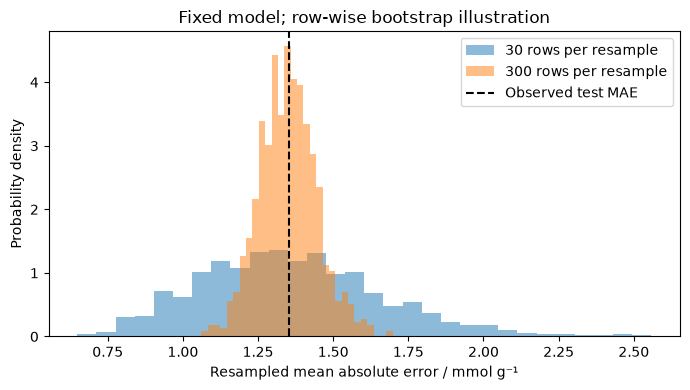

In [8]:
absolute_errors = np.abs(test_predictions - test[TARGET].to_numpy())
rng = np.random.default_rng(27)
bootstrap_means = {}
for size in (30, len(test)):
    bootstrap_means[size] = rng.choice(absolute_errors, size=(1000, size), replace=True).mean(axis=1)
    low, high = np.quantile(bootstrap_means[size], [0.025, 0.975])
    print(f'{size} rows per resample: middle 95% of bootstrap means = {low:.3f} to {high:.3f} mmol/g')
fig, ax = plt.subplots(figsize=(7, 4))
for size, means in bootstrap_means.items():
    ax.hist(means, bins=30, density=True, alpha=0.5, label=f'{size} rows per resample')
ax.axvline(test_mae, color='black', linestyle='--', label='Observed test MAE')
ax.set(xlabel='Resampled mean absolute error / mmol g⁻¹', ylabel='Probability density',
       title='Fixed model; row-wise bootstrap illustration')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Check assisted code and write a claim

Ask an LLM for a function that computes mean absolute error. Before running
its suggestion, predict the answer for residuals −2, 0, +1 mmol/g. It should
be 1 mmol/g. Check exact predictions too. Use the verified library below if
a chatbot is unavailable. Explain the difference from averaging signed errors.

In [9]:
observations = np.array([2., 2., 2.])
predictions = np.array([0., 2., 3.])
assert np.isclose(mean_absolute_error(observations, predictions), 1.0)
assert mean_absolute_error(observations, observations) == 0.0
print('MAE checks passed.')

MAE checks passed.


Complete these three statements using your recorded results:

1. We chose ___ using ___ observations and the ___ metric.
2. On ___ held-out rows, the empirical test MAE was ___ mmol/g. Its relevance
   to future use depends on ___; the bootstrap illustration assumes ___.
3. Before claiming useful experimental CO₂ capture, I would need ___ because ___.

### Sources and reuse

Kevin Jablonka, [MolSim 2024 notebook and data](https://github.com/kjappelbaum/ml_molsim/tree/0ebed176b972c9ba9ddf7b6e3a4d04eaf3f32409), revision
`0ebed176b972`. The source MIT notice is retained in
`data/mof-uptake/LICENSE-ml_molsim.txt`; `provenance.json` records hashes and
subset selection. See the data README for column definitions and limitations.

Optional implementation references: [Kernel ridge regression](https://scikit-learn.org/stable/modules/kernel_ridge.html),
[pipelines](https://scikit-learn.org/stable/modules/compose.html),
[permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html),
and [SciPy's bootstrap documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html).